<a href="https://colab.research.google.com/github/cleristoncramos/Previsao_Financial_Risk/blob/main/TCC_Previsao_Riscos_Financeiros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Previsão de Riscos Financeiros com Data Science e Machine Learning

**Autora:** Lorrana Evelyn de Araújo Pereira
**Orientador:** Prof. Dr. Arlino Henrique Magalhães de Araújo
**Curso:** Tecnologia em Gestão de Dados (UFPI / CEAD)

Este notebook reproduz, passo a passo, a metodologia do trabalho. Ele usa as mesmas funções do pacote `src/` empregadas pelo pipeline (`main.py`) e pelo painel Streamlit, de modo que os resultados aqui são os mesmos do painel e da documentação técnica.

| Seção | Etapa | Descrição |
|---|---|---|
| 1 | Ambiente | Preparação no Colab ou localmente e importações |
| 2 | Coleta de dados | Séries diárias do Yahoo Finance e engenharia de atributos |
| 3 | Análise exploratória | Tendência, volatilidade, distribuição dos retornos e correlação |
| 4 | Pré-processamento | Variável-alvo t+1, divisão temporal 80/20 e padronização |
| 5 | Modelagem | XGBoost, LightGBM e Rede Neural MLP |
| 6 | Avaliação | Comparação com o baseline de persistência e validação cruzada temporal |
| 7 | Interpretabilidade | SHAP e LIME |
| 8 | Risco projetado | Volatilidade do próximo pregão, regime de risco e Value at Risk |
| 9 | Relatório | Relatório consolidado de desempenho |

---
## 1. Ambiente

No Google Colab, a célula abaixo clona o repositório (que inclui o pacote `src/` e os dados coletados) e instala as dependências. Localmente, basta abrir o notebook na raiz do projeto com o ambiente virtual ativado.

In [1]:
import sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
REPOSITORIO = "https://github.com/cleristoncramos/Previsao_Financial_Risk.git"

if EM_COLAB:
    if not Path("Previsao_Financial_Risk").exists():
        !git clone -q {REPOSITORIO}
    %cd Previsao_Financial_Risk
    !pip install -q -r requirements.txt

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    raise FileNotFoundError("Execute o notebook a partir da raiz do projeto (pasta que contém src/).")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print(f"Raiz do projeto: {RAIZ}")

Raiz do projeto: C:\Users\User\OneDrive - mppi.mp.br\Documentos\Previsao_Financial_Risk\Previsao_Financial_Risk


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit
import shap
import lime.lime_tabular
import tensorflow as tf
import xgboost as xgb
import lightgbm as lgb

from src.config import ATIVOS, DATA_INICIO, TICKER_REF, FEATURES, RANDOM_STATE, agora_brasilia
from src.data_collection import carregar_ativo_local, coletar_todos_ativos
from src.preprocessing import preparar_dados_modelagem
from src.models import treinar_todos_modelos
from src.evaluation import avaliar_todos_modelos, adicionar_baseline_ingenuo, validacao_cruzada_temporal
from src.figuras import triangulo_inferior
from src.report import montar_texto_relatorio

# src.figuras fixa o backend "Agg" do Matplotlib (exigido pelo painel); aqui as figuras voltam a ser exibidas
%matplotlib inline

if not EM_COLAB:
    pio.renderers.default = "plotly_mimetype+notebook_connected"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.formatter.use_locale"] = False


def br(valor, casas=2):
    """Formata um número no padrão brasileiro (milhar com ponto e decimal com vírgula)."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


print(f"TensorFlow {tf.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__} | SHAP {shap.__version__}")

TensorFlow 2.22.0-rc0 | XGBoost 3.4.1 | LightGBM 4.7.0 | SHAP 0.54.1


---
## 2. Coleta de dados

Séries diárias do Yahoo Finance (`yfinance`, preços ajustados por proventos e desdobramentos) de cinco ações da B3 e de dois índices, de 2016 até a data da coleta. Para cada série, `engenharia_atributos()` calcula retorno diário, volatilidade anualizada de 21 pregões, médias móveis de 20 e 50 pregões, RSI de 14 pregões e média de volume de 20 pregões.

Com `USAR_DADOS_LOCAIS = True`, o notebook usa os CSVs de `dados_coletados/` (os mesmos do painel), o que torna os resultados reprodutíveis. Com `False`, baixa as séries novamente e substitui os CSVs.

In [3]:
USAR_DADOS_LOCAIS = True

if USAR_DADOS_LOCAIS:
    dados = {}
    for categoria, tickers in ATIVOS.items():
        for ticker in tickers:
            df = carregar_ativo_local(ticker, categoria)
            if df is not None:
                dados[ticker] = df
    if len(dados) < sum(len(t) for t in ATIVOS.values()):
        print("CSVs incompletos; baixando as séries no Yahoo Finance.")
        dados = coletar_todos_ativos()
else:
    dados = coletar_todos_ativos()

resumo = pd.DataFrame(
    {
        "Registros": [len(df) for df in dados.values()],
        "Início": [f"{df['Data'].min():%d/%m/%Y}" for df in dados.values()],
        "Fim": [f"{df['Data'].max():%d/%m/%Y}" for df in dados.values()],
    },
    index=list(dados),
)
resumo

,Registros,Início,Fim
PETR4.SA,2692,04/01/2016,21/10/2026
VALE3.SA,2692,04/01/2016,21/10/2026
ITUB4.SA,2692,04/01/2016,21/10/2026
BBDC4.SA,2692,04/01/2016,21/10/2026
ABEV3.SA,2692,04/01/2016,21/10/2026
^BVSP,2684,04/01/2016,21/10/2026
^GSPC,2716,04/01/2016,21/10/2026


---
## 3. Análise exploratória

O ativo de referência da modelagem é o **IBOVESPA (^BVSP)**. As primeiras linhas, sem histórico suficiente para as janelas móveis (até 50 pregões), são descartadas.

In [4]:
df_ref = dados[TICKER_REF].dropna(subset=FEATURES).reset_index(drop=True)
print(f"Pregões com todos os atributos: {br(len(df_ref), 0)}")
print(f"Período: {df_ref['Data'].min():%d/%m/%Y} a {df_ref['Data'].max():%d/%m/%Y}")
df_ref.tail()

Pregões com todos os atributos: 2.633
Período: 16/03/2016 a 21/10/2026


,Data,Close,High,Low,Open,Volume,Retorno_Diario,Volatilidade_21d,MM_20d,MM_50d,RSI_14d,Volume_MM20
2628,2026-10-15,204324.0,206520.0,203110.0,206487.0,11058200,-0.010566,0.303615,194051.15,183577.46,77.500405,12387365.0
2629,2026-10-16,205430.0,206305.0,204164.0,204324.0,11061400,0.005413,0.301586,195023.05,184131.54,79.168770,12509310.0
2630,2026-10-19,205079.0,207388.0,204269.0,205440.0,9350600,-0.001709,0.302370,196015.55,184722.20,79.453808,12403665.0
2631,2026-10-20,208296.0,208942.0,205082.0,205082.0,11417200,0.015687,0.302775,197100.55,185437.86,80.680108,12541365.0
2632,2026-10-21,206495.0,209245.0,205988.0,208296.0,9682800,-0.008646,0.306766,198054.15,186124.16,75.730882,12546005.0


In [5]:
colunas_num = ["Close", "Volume", "Retorno_Diario", "Volatilidade_21d", "MM_20d", "MM_50d", "RSI_14d"]
df_ref[colunas_num].describe().round(4)

,Close,Volume,Retorno_Diario,Volatilidade_21d,MM_20d,MM_50d,RSI_14d
count,2633.0000,2.633000e+03,2633.0000,2633.0000,2633.0000,2633.0000,2633.0000
mean,108152.0881,8.017820e+06,0.0007,0.2001,107594.2775,106765.4437,54.2496
std,32142.6465,4.084609e+06,0.0144,0.1119,31726.1841,31345.6854,17.2607
min,47763.0000,0.000000e+00,-0.1478,0.0669,45620.6500,42063.4000,4.8685
25%,84985.0000,4.206400e+06,-0.0065,0.1464,84714.8000,83935.0200,41.9481
50%,108844.0000,8.212400e+06,0.0006,0.1805,108410.6500,108378.6600,52.9658
75%,125970.0000,1.083370e+07,0.0083,0.2260,126120.7000,124722.2400,66.6728
max,209067.0000,2.906030e+07,0.1391,1.2683,198054.1500,187371.4200,99.7257


O volume mínimo igual a zero corresponde a pregões em que o Yahoo Finance não informa o volume do índice. Esses dias são mantidos, pois o preço e a volatilidade estão disponíveis, mas é uma limitação de qualidade da fonte.

In [6]:
print(f"Pregões com volume zero: {(df_ref['Volume'] == 0).sum()}")

fig = go.Figure()
fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["Close"], name="Fechamento", line=dict(color="#1e3a8a", width=1.2)))
fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["MM_20d"], name="MM 20d", line=dict(color="#c2410c", dash="dash")))
fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["MM_50d"], name="MM 50d", line=dict(color="#15803d", dash="dot")))
fig.update_layout(
    title="IBOVESPA: preço de fechamento e médias móveis",
    xaxis_title="Data", yaxis_title="Pontos", hovermode="x unified",
    template="plotly_white", height=420, separators=",.", legend=dict(orientation="h", y=1.02),
)
fig.show()

Pregões com volume zero: 30


In [7]:
fig = px.area(
    df_ref, x="Data", y="Volatilidade_21d",
    title="IBOVESPA: volatilidade histórica anualizada (janela de 21 pregões)",
    labels={"Volatilidade_21d": "Volatilidade anualizada"},
    color_discrete_sequence=["#b91c1c"], template="plotly_white", height=380,
)
fig.update_layout(separators=",.", yaxis_tickformat=".0%")
fig.show()

pico = df_ref.loc[df_ref["Volatilidade_21d"].idxmax()]
print(f"Volatilidade máxima: {br(pico['Volatilidade_21d'] * 100, 1)}% em {pico['Data']:%d/%m/%Y}")

Volatilidade máxima: 126,8% em 06/04/2020


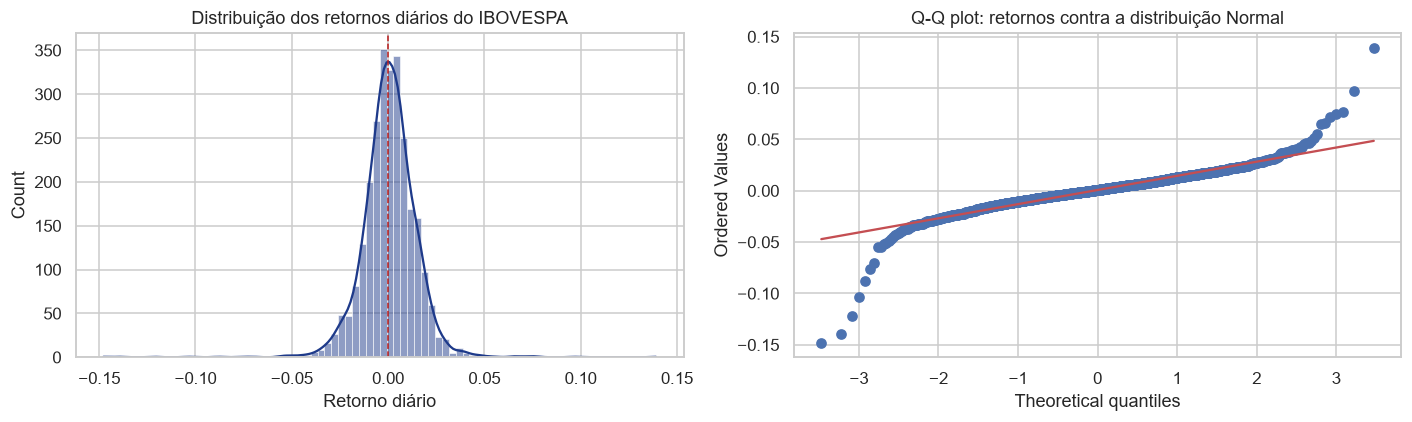

Assimetria: -0,6940
Curtose em excesso: 15,3935 (curtose de 18,39, contra 3 da Normal)
A curtose em excesso positiva indica caudas pesadas (distribuição leptocúrtica), típicas de séries financeiras.


In [8]:
# Todos os retornos da série, como no painel (inclui os pregões anteriores às janelas de 50 dias)
retornos_ref = dados[TICKER_REF]["Retorno_Diario"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(retornos_ref, bins=80, kde=True, color="#1e3a8a", ax=axes[0])
axes[0].axvline(0, color="#b91c1c", linestyle="--", linewidth=1)
axes[0].set_title("Distribuição dos retornos diários do IBOVESPA")
axes[0].set_xlabel("Retorno diário")
stats.probplot(retornos_ref, plot=axes[1])
axes[1].set_title("Q-Q plot: retornos contra a distribuição Normal")
plt.tight_layout()
plt.show()

assimetria = retornos_ref.skew()
curtose_excesso = retornos_ref.kurtosis()  # Fisher: vale 0 para a Normal
print(f"Assimetria: {br(assimetria, 4)}")
print(f"Curtose em excesso: {br(curtose_excesso, 4)} (curtose de {br(curtose_excesso + 3, 2)}, contra 3 da Normal)")
print("A curtose em excesso positiva indica caudas pesadas (distribuição leptocúrtica), típicas de séries financeiras.")

### Correlação dos retornos entre os ativos

Os retornos são alinhados **pela data do pregão**: as séries têm calendários diferentes (feriados da B3 e da bolsa americana), e só entram os dias em que todos os ativos negociaram. A matriz mostra o triângulo inferior, com cada par de ativos uma única vez.

Pregões em comum: 2.613


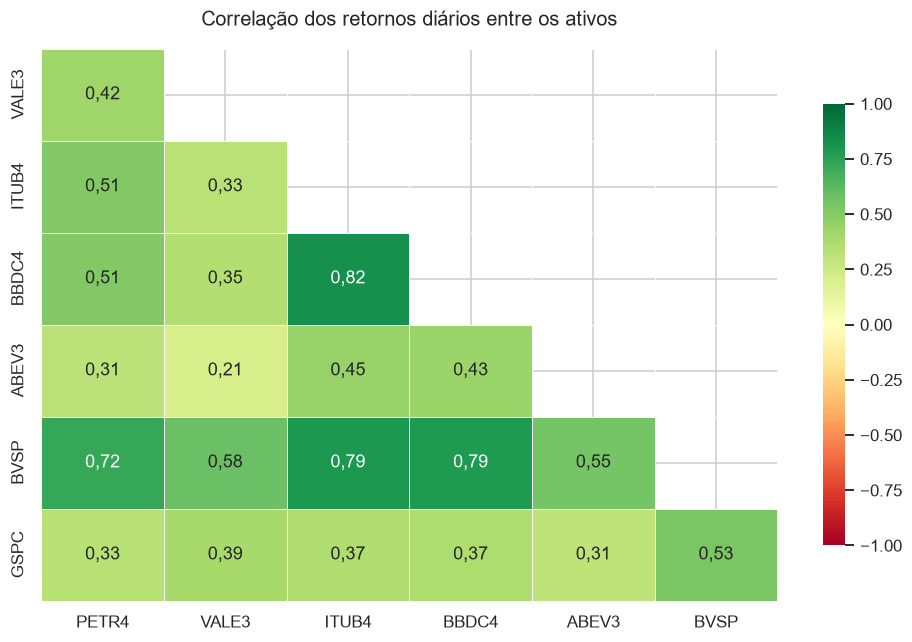

In [9]:
retornos = pd.DataFrame(
    {t.replace(".SA", "").replace("^", ""): df.set_index("Data")["Retorno_Diario"] for t, df in dados.items()}
).dropna()
corr = triangulo_inferior(retornos.corr())
print(f"Pregões em comum: {br(len(retornos), 0)}")

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, ax=ax,
            linewidths=.5, cbar_kws={"shrink": .8})
for texto in ax.texts:
    texto.set_text(texto.get_text().replace(".", ","))
ax.set_title("Correlação dos retornos diários entre os ativos", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

---
## 4. Pré-processamento

- **Variável-alvo:** volatilidade do pregão seguinte, `Volatilidade_21d` deslocada um período (`shift(-1)`).
- **Atributos:** as oito variáveis técnicas do pregão atual.
- **Divisão:** temporal, sem embaralhamento: os primeiros 80% para treino e os 20% finais para teste.
- **Padronização:** `StandardScaler` ajustado apenas no treino, evitando vazamento de informação do teste.

In [10]:
dataset = preparar_dados_modelagem(dados[TICKER_REF])

datas_treino = pd.to_datetime(dataset.datas_train)
datas_teste = pd.to_datetime(dataset.datas_test)
print(f"\nTreino: {br(len(dataset.X_train), 0)} amostras ({datas_treino[0]:%d/%m/%Y} a {datas_treino[-1]:%d/%m/%Y})")
print(f"Teste : {br(len(dataset.X_test), 0)} amostras ({datas_teste[0]:%d/%m/%Y} a {datas_teste[-1]:%d/%m/%Y})")


 ETAPA 4: PRÉ-PROCESSAMENTO & PREPARAÇÃO PARA MODELAGEM
  Amostras Treino : 2105 (80%)
  Amostras Teste  : 527 (20%)
  Features (8) : ['Close', 'Volume', 'Retorno_Diario', 'Volatilidade_21d', 'MM_20d', 'MM_50d', 'RSI_14d', 'Volume_MM20']
  Target         : Target_Vol (Volatilidade do dia seguinte - t+1)

Treino: 2.105 amostras (16/03/2016 a 04/09/2024)
Teste : 527 amostras (05/09/2024 a 20/10/2026)


---
## 5. Modelagem

`treinar_todos_modelos()` treina, em sequência, os três modelos com os hiperparâmetros de `src/config.py`:

- **XGBoost** e **LightGBM:** 500 árvores, taxa de aprendizado 0,05. O conjunto de teste não é usado no ajuste nem monitorado durante o treino.
- **Rede Neural MLP:** camadas de 128, 64 e 32 neurônios com ReLU, Dropout de 10% e camada `Rescaling` na saída (a rede aprende o alvo padronizado e devolve a volatilidade na escala original). O *Early Stopping* monitora os **últimos 15% do treino**, nunca o teste.

Os modelos não são salvos aqui (`salvar=False`), para não substituir os modelos usados pelo painel. As métricas da MLP variam entre execuções, porque o treinamento da rede no TensorFlow não é totalmente determinístico; por isso podem diferir das do modelo salvo exibido no painel. XGBoost, LightGBM e o baseline são determinísticos e coincidem com o painel.

In [11]:
modelos, predicoes, extras = treinar_todos_modelos(dataset, salvar=False)
modelo_xgb = modelos["XGBoost"]
history = extras["history_nn"]


 ETAPA 5: MODELAGEM PREDITIVA (MACHINE LEARNING & DEEP LEARNING)
  -> [1/3] Treinando XGBoost...


  [OK] XGBoost concluído com sucesso!
  -> [2/3] Treinando LightGBM...


  [OK] LightGBM concluído com sucesso!
  -> [3/3] Treinando Rede Neural (MLP)...


  [OK] Rede Neural concluída! (28 épocas executadas)


---
## 6. Avaliação

### 6.1. Comparação com o baseline de persistência

O **baseline de persistência** repete a volatilidade do pregão atual como previsão do seguinte ($\hat{\sigma}_{t+1} = \sigma_t$). Como 20 dos 21 retornos da janela se repetem de um pregão para o outro, a volatilidade em janela móvel é muito persistente, e esse baseline é a régua mínima que um modelo precisa superar.

In [12]:
predicoes_todas = adicionar_baseline_ingenuo(dataset.features, dataset.X_test, predicoes)
df_resultados = avaliar_todos_modelos(dataset.y_test, predicoes_todas)

tabela = df_resultados.copy()
for coluna, casas in [("RMSE", 5), ("MAE", 5), ("R2", 4)]:
    tabela[coluna] = tabela[coluna].map(lambda v: br(v, casas))
tabela.rename(columns={"R2": "R²"}).set_index("Modelo")


 ETAPA 6: AVALIAÇÃO DE DESEMPENHO DOS MODELOS
  [XGBoost           ]  RMSE: 0.01407  |  MAE: 0.00897  |  R²: 0.9014
  [LightGBM          ]  RMSE: 0.01497  |  MAE: 0.00961  |  R²: 0.8883
  [Rede Neural (MLP) ]  RMSE: 0.01623  |  MAE: 0.01096  |  R²: 0.8687
  [Baseline Ingênuo (Persistência)]  RMSE: 0.01186  |  MAE: 0.00603  |  R²: 0.9299


,RMSE,MAE,R²
Modelo,,,
Baseline Ingênuo (Persistência),"0,01186","0,00603","0,9299"
XGBoost,"0,01407","0,00897","0,9014"
LightGBM,"0,01497","0,00961","0,8883"
Rede Neural (MLP),"0,01623","0,01096","0,8687"


In [13]:
eh_baseline = df_resultados["Modelo"].str.contains("Baseline")
rmse_baseline = df_resultados.loc[eh_baseline, "RMSE"].iloc[0]
melhor_ml = df_resultados[~eh_baseline].iloc[0]
diferenca = (melhor_ml["RMSE"] - rmse_baseline) / rmse_baseline * 100

print(f"Melhor modelo de ML: {melhor_ml['Modelo']} (RMSE {br(melhor_ml['RMSE'], 5)})")
print(f"Baseline de persistência: RMSE {br(rmse_baseline, 5)}")
if diferenca > 0:
    print(f"O RMSE do modelo ficou {br(diferenca, 1)}% acima do baseline: neste horizonte, a persistência não foi superada.")
else:
    print(f"O RMSE do modelo ficou {br(-diferenca, 1)}% abaixo do baseline.")

Melhor modelo de ML: XGBoost (RMSE 0,01407)
Baseline de persistência: RMSE 0,01186
O RMSE do modelo ficou 18,6% acima do baseline: neste horizonte, a persistência não foi superada.


In [14]:
cores = {"XGBoost": "#c2410c", "LightGBM": "#15803d", "Rede Neural (MLP)": "#7c3aed", "Baseline Ingênuo (Persistência)": "#6b7280"}
tracos = {"XGBoost": "dash", "LightGBM": "dot", "Rede Neural (MLP)": "dashdot", "Baseline Ingênuo (Persistência)": "longdash"}

fig = go.Figure()
fig.add_trace(go.Scatter(x=datas_teste, y=dataset.y_test, name="Real", line=dict(color="#1e3a8a", width=2)))
for nome, previsao in predicoes_todas.items():
    fig.add_trace(go.Scatter(x=datas_teste, y=previsao, name=nome, line=dict(color=cores[nome], dash=tracos[nome], width=1.3)))
fig.update_layout(
    title="Volatilidade do pregão seguinte: real contra previsões (conjunto de teste)",
    xaxis_title="Data", yaxis_title="Volatilidade anualizada", yaxis_tickformat=".0%",
    hovermode="x unified", template="plotly_white", height=450, separators=",.",
    legend=dict(orientation="h", y=1.02),
)
fig.show()

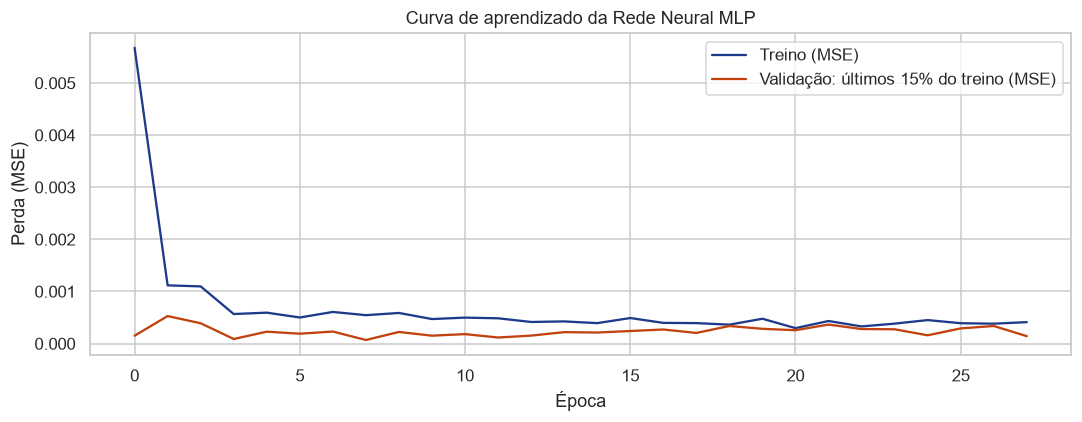

Épocas executadas: 28


In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history["loss"], label="Treino (MSE)", color="#1e3a8a")
ax.plot(history.history["val_loss"], label="Validação: últimos 15% do treino (MSE)", color="#c2410c")
ax.set_title("Curva de aprendizado da Rede Neural MLP")
ax.set_xlabel("Época")
ax.set_ylabel("Perda (MSE)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Épocas executadas: {len(history.epoch)}")

### 6.2. Validação cruzada temporal

`TimeSeriesSplit` com 5 folds sobre a série completa: cada fold treina com todo o passado disponível e valida no bloco seguinte, com o *scaler* ajustado dentro do fold. Assim se avalia a estabilidade do XGBoost em diferentes períodos de mercado.

In [16]:
rmses = validacao_cruzada_temporal(dataset.X, dataset.y, n_splits=5)

datas_serie = pd.to_datetime(dataset.datas)
linhas_folds = []
for i, (tr_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(dataset.X)):
    linhas_folds.append({
        "Fold": f"Fold {i + 1}",
        "Treino": f"{datas_serie[tr_idx[0]]:%d/%m/%Y} a {datas_serie[tr_idx[-1]]:%d/%m/%Y} ({br(len(tr_idx), 0)})",
        "Período de Validação": f"{datas_serie[val_idx[0]]:%m/%Y}–{datas_serie[val_idx[-1]]:%m/%Y}",
        "RMSE": rmses[i],
    })
folds = pd.DataFrame(linhas_folds)

print(f"\nMédia: {br(np.mean(rmses), 5)} ± {br(np.std(rmses), 5)}")
folds.assign(RMSE=folds["RMSE"].map(lambda v: br(v, 5))).set_index("Fold")


-> Validação Cruzada Temporal (5 folds) — XGBoost...


   Fold 1: RMSE = 0.01796


   Fold 2: RMSE = 0.19518


   Fold 3: RMSE = 0.01311


   Fold 4: RMSE = 0.01093


   Fold 5: RMSE = 0.01358
  ==> Média RMSE CV: 0.05015  ±  0.07255

Média: 0,05015 ± 0,07255


,Treino,Período de Validação,RMSE
Fold,,,
Fold 1,16/03/2016 a 21/12/2017 (442),12/2017–10/2019,"0,01796"
Fold 2,16/03/2016 a 01/10/2019 (880),10/2019–07/2021,"0,19518"
Fold 3,16/03/2016 a 13/07/2021 (1.318),07/2021–04/2023,"0,01311"
Fold 4,16/03/2016 a 13/04/2023 (1.756),04/2023–01/2025,"0,01093"
Fold 5,16/03/2016 a 15/01/2025 (2.194),01/2025–10/2026,"0,01358"


O fold 2 concentra o erro: seu período de validação inclui o choque da pandemia de 2020, quando a volatilidade do IBOVESPA atingiu níveis muito acima de tudo o que o modelo havia visto no treino.

---
## 7. Interpretabilidade

**SHAP** (*SHapley Additive exPlanations*) decompõe cada previsão do XGBoost na soma das contribuições das variáveis. **LIME** (*Local Interpretable Model-agnostic Explanations*) aproxima o modelo, em torno de um pregão, por um modelo linear interpretável.

Média de |SHAP| no conjunto de teste:
  Volatilidade_21d  0,04607
  Close             0,01526
  MM_50d            0,01011
  MM_20d            0,00838
  Volume_MM20       0,00308
  Retorno_Diario    0,00178
  RSI_14d           0,00112
  Volume            0,00085


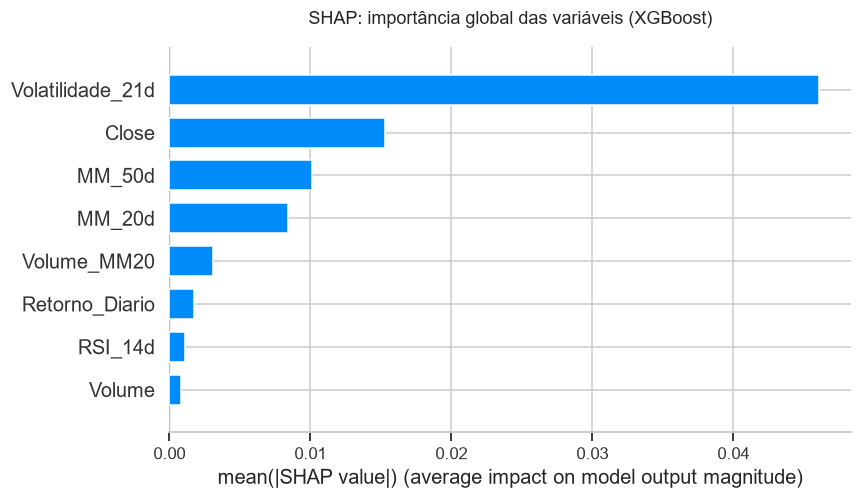

In [17]:
explainer_shap = shap.TreeExplainer(modelo_xgb)
shap_values = explainer_shap.shap_values(dataset.X_test_scaled)
base_shap = float(np.ravel(explainer_shap.expected_value)[0])

importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=dataset.features).sort_values(ascending=False)
print("Média de |SHAP| no conjunto de teste:")
for variavel, valor in importancia.items():
    print(f"  {variavel:<17} {br(valor, 5)}")

plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, dataset.X_test_scaled, feature_names=dataset.features, plot_type="bar", show=False)
plt.title("SHAP: importância global das variáveis (XGBoost)", pad=15)
plt.tight_layout()
plt.show()

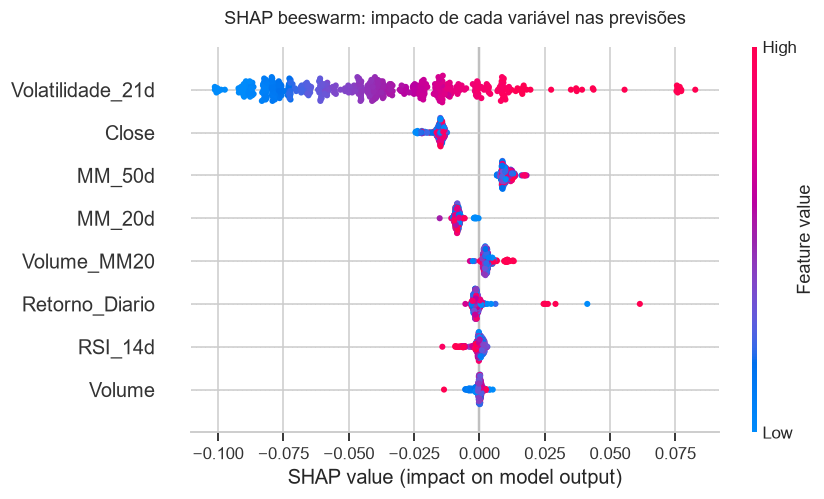

In [18]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, dataset.X_test_scaled, feature_names=dataset.features, show=False)
plt.title("SHAP beeswarm: impacto de cada variável nas previsões", pad=15)
plt.tight_layout()
plt.show()

### Explicação de um pregão

O waterfall do SHAP e o LIME exibem as variáveis na **escala original** (pontos, volume, percentuais), como no painel. No LIME, o *scaler* é aplicado dentro da função de previsão, de modo que as condições ficam legíveis.

Pregão explicado: índice 10 do teste, 19/09/2024


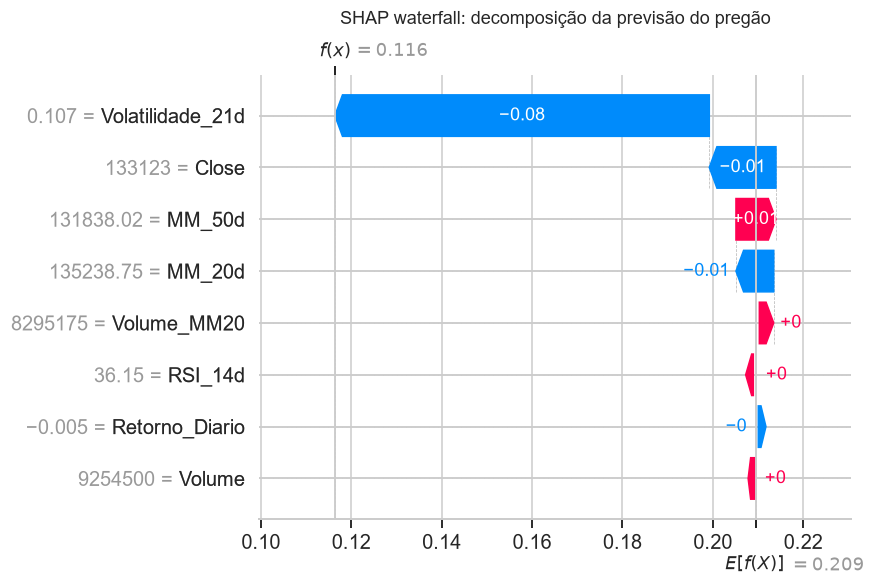

In [19]:
idx_exemplo = 10
print(f"Pregão explicado: índice {idx_exemplo} do teste, {datas_teste[idx_exemplo]:%d/%m/%Y}")

explicacao = shap.Explanation(
    values=shap_values[idx_exemplo],
    base_values=base_shap,
    data=dataset.X_test[idx_exemplo],
    feature_names=dataset.features,
)
shap.plots.waterfall(explicacao, show=False)
plt.title("SHAP waterfall: decomposição da previsão do pregão", pad=12)
plt.tight_layout()
plt.show()

Previsão do XGBoost: 11,64%
Valor real         : 11,50%


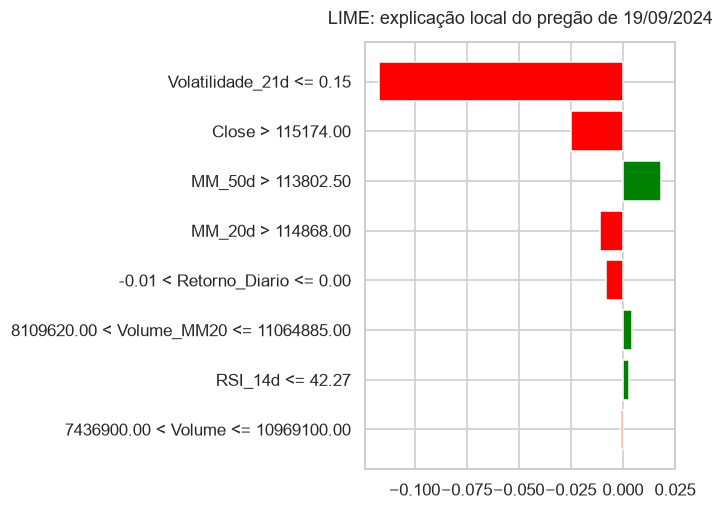

In [20]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=dataset.X_train,
    feature_names=dataset.features,
    mode="regression",
    random_state=RANDOM_STATE,
)
exp_lime = explainer_lime.explain_instance(
    dataset.X_test[idx_exemplo],
    lambda X: modelo_xgb.predict(dataset.scaler.transform(X)),
    num_features=len(dataset.features),
)

print(f"Previsão do XGBoost: {br(predicoes['XGBoost'][idx_exemplo] * 100, 2)}%")
print(f"Valor real         : {br(dataset.y_test[idx_exemplo] * 100, 2)}%")
exp_lime.as_pyplot_figure()
plt.title(f"LIME: explicação local do pregão de {datas_teste[idx_exemplo]:%d/%m/%Y}", pad=12)
plt.tight_layout()
plt.show()

---
## 8. Risco projetado e Value at Risk

O XGBoost projeta a volatilidade do pregão seguinte ao último pregão disponível. A projeção é classificada pelos percentis da volatilidade histórica do próprio ativo e convertida em **Value at Risk paramétrico de um dia**:

$$VaR_{\alpha} = z_{\alpha} \times \frac{\hat{\sigma}_{anual}}{\sqrt{252}} \times W$$

com $z_{95\%} = 1{,}644853$, $z_{99\%} = 2{,}326348$ e $W$ o patrimônio exposto. O modelo assume retornos normais; diante das caudas pesadas observadas na seção 3, tende a subestimar perdas extremas.

In [21]:
PATRIMONIO = 100_000.0

# Último pregão com todos os atributos: ele não entra na modelagem, pois ainda não tem t+1
ultima_linha = dados[TICKER_REF][["Data"] + FEATURES].dropna().iloc[-1]
x_ultimo = ultima_linha[FEATURES].to_numpy(dtype=float).reshape(1, -1)
vol_projetada = float(modelo_xgb.predict(dataset.scaler.transform(x_ultimo))[0])

vol_hist = dados[TICKER_REF]["Volatilidade_21d"].dropna()
p25, p75, p95 = np.percentile(vol_hist, [25, 75, 95])
if vol_projetada < p25:
    regime = "Baixo"
elif vol_projetada < p75:
    regime = "Moderado"
elif vol_projetada < p95:
    regime = "Elevado"
else:
    regime = "Extremo"

vol_diaria = vol_projetada / np.sqrt(252)
var_95 = 1.644853 * vol_diaria * PATRIMONIO
var_99 = 2.326348 * vol_diaria * PATRIMONIO

print(f"Pregão base             : {ultima_linha['Data']:%d/%m/%Y}")
print(f"Volatilidade projetada  : {br(vol_projetada * 100, 2)}% ao ano")
print(f"Limites históricos      : P25 {br(p25 * 100, 2)}% | P75 {br(p75 * 100, 2)}% | P95 {br(p95 * 100, 2)}%")
print(f"Regime de risco         : {regime}")
print(f"VaR de 1 dia (95%)      : R$ {br(var_95)} para R$ {br(PATRIMONIO)}")
print(f"VaR de 1 dia (99%)      : R$ {br(var_99)} para R$ {br(PATRIMONIO)}")

Pregão base             : 21/10/2026
Volatilidade projetada  : 28,30% ao ano
Limites históricos      : P25 14,66% | P75 22,78% | P95 32,63%
Regime de risco         : Elevado
VaR de 1 dia (95%)      : R$ 2.932,22 para R$ 100.000,00
VaR de 1 dia (99%)      : R$ 4.147,09 para R$ 100.000,00


---
## 9. Relatório consolidado

Mesmo relatório gerado pela aba **Relatórios e Downloads** do painel, com data e hora no fuso de Brasília.

In [22]:
df_serie = dados[TICKER_REF]
relatorio = montar_texto_relatorio(
    df_resultados,
    ticker_ref=TICKER_REF,
    data_inicio=df_serie["Data"].min(),
    data_fim=df_serie["Data"].max(),
    n_train=len(dataset.X_train),
    n_test=len(dataset.X_test),
    gerado_em=agora_brasilia(),
    periodo_teste=(dataset.datas_test[0], dataset.datas_test[-1]),
    nome_ativo="IBOVESPA",
    periodo_treino=(dataset.datas_train[0], dataset.datas_train[-1]),
    folds=folds,
)
print(relatorio)

  RELATÓRIO CONSOLIDADO DE DESEMPENHO DOS MODELOS
  TCC — Previsão de Riscos Financeiros com Data Science e Machine Learning
  Autora: Lorrana Evelyn de Araújo Pereira
  Curso: Tecnologia em Gestão de Dados — UFPI / CEAD
  Gerado em: 23/10/2026 às 10:44

  1. DADOS E METODOLOGIA
  ------------------------------------------------------------------------------
  Ativo analisado   : ^BVSP (IBOVESPA)
  Período da série  : 04/01/2016 a 21/10/2026
  Conjunto de treino: 2.105 amostras (16/03/2016 a 04/09/2024)
  Conjunto de teste : 527 amostras (05/09/2024 a 20/10/2026)
  Divisão           : temporal 80/20, sem embaralhamento
  Variável-alvo     : volatilidade histórica anualizada (21 dias) em t+1

  2. DESEMPENHO NO CONJUNTO DE TESTE (ordenado por RMSE)
  ------------------------------------------------------------------------------
  Modelo                                 RMSE       MAE       R²   Classificação
  ------------------------------------------------------------------------------

---
## Painel interativo

A exploração interativa de todos os ativos (análise exploratória, desempenho, SHAP e LIME por pregão, simulador de VaR e downloads) está no painel Streamlit do projeto:

```bash
streamlit run app.py
```